# AI vs Real Image Detection - AIForensicNet (Custom Architecture)

Notebook ini melatih arsitektur model kustom orisinal **AIForensicNet** yang dibangun murni dari nol (*from scratch*) tanpa bergantung pada model pre-trained pihak ketiga (ImageNet).

### Inovasi Arsitektur AIForensicNet:
1. **Dual-Stream Input**:
   - **Stream 1 (High-Pass Residual)**: Menggunakan filter Laplacian untuk menekan konten semantik objek dan secara spesifik mengisolasi *noise residual*, artefak *checkerboard*, dan inkonsistensi frekuensi tinggi buatan model generatif (Diffusion/GAN).
   - **Stream 2 (RGB Spasial)**: Mengekstraksi koherensi pencahayaan, tekstur permukaan, dan gradasi warna alami.
2. **Hierarchical Residual Backbone (ConvNeXt-Style)**: Menggunakan konvolusi Depthwise 7x7 dengan *receptive field* luas yang dipadukan dengan *Pointwise projection*.
3. **Squeeze-and-Excitation (SE) Attention**: Secara otomatis memberi bobot ekstra pada kanal fitur yang paling reaktif terhadap kejanggalan sintesis gambar AI.
4. **Ultra-Lightweight & Fast**: Hanya berukuran **~2.85 Juta Parameter** (10x lebih kecil dari ConvNeXt-Tiny). Konsumsi VRAM di bawah **1.0 GB**.

### Konfigurasi Pelatihan:
- **Dataset**: `Thunderbeast/AI-Generated-vs-Real-Images-Datasets` (Hugging Face)
- **Optimizer**: AdamW (`lr=3e-4`, `weight_decay=1e-2`) + `CosineAnnealingLR`
- **Akselerasi**: Automatic Mixed Precision (AMP FP16) + cuDNN Benchmark
- **Output Checkpoint**: `best_aiforensicnet_ai_vs_real.pth`

In [1]:
import warnings
warnings.filterwarnings('ignore', message='.*Palette images with Transparency.*')
warnings.filterwarnings('ignore', message='.*xFormers is not available.*')

import os
import copy
import time
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR
from torchvision import transforms
from datasets import load_dataset

# Memeriksa dan menetapkan hardware acceleration (GPU jika tersedia)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
    print(f"Device yang digunakan: {device} ({torch.cuda.get_device_name(0)})")
    print("[Akselerasi GPU] cuDNN Benchmark diaktifkan!")
else:
    print(f"Device yang digunakan: {device}")

Device yang digunakan: cuda (NVIDIA GeForce RTX 4050 Laptop GPU)
[Akselerasi GPU] cuDNN Benchmark diaktifkan!


In [2]:
print("=" * 65)
print("MEMUAT DATASET DARI HUGGING FACE (Thunderbeast)")
print("=" * 65)

# Load dataset Thunderbeast/AI-Generated-vs-Real-Images-Datasets
dataset = load_dataset(
    "Thunderbeast/AI-Generated-vs-Real-Images-Datasets",
    split="train",
    cache_dir="./data",
    verification_mode="no_checks"
)

# Bagi dataset secara seimbang (stratified) menjadi 90% Training dan 10% Validasi
splits = dataset.train_test_split(test_size=0.10, stratify_by_column="label", seed=42)
train_hf = splits["train"]
val_hf = splits["test"]

print(f"Total Data Training : {len(train_hf):,}")
print(f"Total Data Validasi : {len(val_hf):,}")
print(f"Label Kelas Asli    : {dataset.features['label'].names}")
print("=" * 65)

MEMUAT DATASET DARI HUGGING FACE (Thunderbeast)


Total Data Training : 137,439
Total Data Validasi : 15,271
Label Kelas Asli    : ['AiArtData', 'RealArt']


In [3]:
# 1. Transformasi Data Sesuai Input AIForensicNet (224x224)
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. PyTorch Dataset Wrapper dari Hugging Face
class HFToPyTorchDataset(Dataset):
    def __init__(self, hf_dataset, transform=None):
        self.dataset = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]
        image = item["image"]
        label = item["label"]

        if image.mode == 'P' and 'transparency' in image.info:
            image = image.convert('RGBA')
        if image.mode != "RGB":
            image = image.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

# 3. Inisialisasi Dataset & DataLoader
# Model kustom ini sangat hemat VRAM (~0.9 GB)
train_dataset = HFToPyTorchDataset(train_hf, transform=train_transforms)
val_dataset = HFToPyTorchDataset(val_hf, transform=val_transforms)

BATCH_SIZE = 32
use_pin = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=use_pin
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=use_pin
)

print(f"DataLoader Siap!")
print(f"Total Batch Training : {len(train_loader):,} batch (Batch Size: {BATCH_SIZE})")
print(f"Total Batch Validasi : {len(val_loader):,} batch")

DataLoader Siap!
Total Batch Training : 4,295 batch (Batch Size: 32)
Total Batch Validasi : 478 batch


In [4]:
# Definisi Lengkap Arsitektur AIForensicNet (Self-Contained)
class SqueezeExcitation(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        reduced = max(8, channels // reduction)
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(channels, reduced, bias=False),
            nn.GELU(),
            nn.Linear(reduced, channels, bias=False),
            nn.Sigmoid()
        )
    def forward(self, x):
        b, c, _, _ = x.shape
        w = self.fc(x).view(b, c, 1, 1)
        return x * w

class ForensicBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1):
        super().__init__()
        self.dwconv = nn.Conv2d(in_c, in_c, kernel_size=7, stride=stride, padding=3, groups=in_c, bias=False)
        self.norm = nn.BatchNorm2d(in_c)
        self.pwconv1 = nn.Conv2d(in_c, out_c * 2, kernel_size=1)
        self.act = nn.GELU()
        self.pwconv2 = nn.Conv2d(out_c * 2, out_c, kernel_size=1)
        self.se = SqueezeExcitation(out_c)
        
        if stride != 1 or in_c != out_c:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_c, out_c, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_c)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        res = self.shortcut(x)
        out = self.dwconv(x)
        out = self.norm(out)
        out = self.pwconv1(out)
        out = self.act(out)
        out = self.pwconv2(out)
        out = self.se(out)
        return out + res

class AIForensicNet(nn.Module):
    def __init__(self, num_classes=2, dropout_p=0.3):
        super().__init__()
        hp_kernel = torch.tensor([
            [-1., -1., -1.],
            [-1.,  8., -1.],
            [-1., -1., -1.]
        ]).unsqueeze(0).repeat(3, 1, 1, 1)
        self.hp_filter = nn.Parameter(hp_kernel, requires_grad=False)
        
        self.hp_stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.GELU()
        )
        self.rgb_stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.GELU()
        )
        
        self.stage1 = nn.Sequential(ForensicBlock(64, 64), ForensicBlock(64, 64))
        self.stage2 = nn.Sequential(ForensicBlock(64, 128, stride=2), ForensicBlock(128, 128))
        self.stage3 = nn.Sequential(ForensicBlock(128, 256, stride=2), ForensicBlock(256, 256))
        self.stage4 = nn.Sequential(ForensicBlock(256, 512, stride=2), ForensicBlock(512, 512))
        
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(p=dropout_p),
            nn.Linear(512, 128),
            nn.GELU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        hp_x = F.conv2d(x, self.hp_filter, padding=1, groups=3)
        feat_hp = self.hp_stem(hp_x)
        feat_rgb = self.rgb_stem(x)
        out = torch.cat([feat_hp, feat_rgb], dim=1)
        out = self.stage1(out)
        out = self.stage2(out)
        out = self.stage3(out)
        out = self.stage4(out)
        return self.head(out)

model = AIForensicNet(num_classes=2).to(device)

criterion = nn.CrossEntropyLoss()
# Model from scratch optimal pada learning rate 3e-4
optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)

EPOCHS = 5
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=" * 65)
print(f"MODEL KUSTOM AIForensicNet BERHASIL DIINISIALISASI")
print("=" * 65)
print(f"Total Parameter       : {total_params:,} (~2.85 Juta Parameter)")
print(f"Trainable Parameter   : {trainable_params:,} (From Scratch)")
print(f"Arsitektur            : Dual-Stream (High-Pass Residual + Spatial RGB)")
print(f"Learning Rate Awal    : 3.0e-04 (AdamW + CosineAnnealingLR)")
print("=" * 65)

MODEL KUSTOM AIForensicNet BERHASIL DIINISIALISASI
Total Parameter       : 2,851,741 (~2.85 Juta Parameter)
Trainable Parameter   : 2,851,714 (From Scratch)
Arsitektur            : Dual-Stream (High-Pass Residual + Spatial RGB)
Learning Rate Awal    : 3.0e-04 (AdamW + CosineAnnealingLR)


In [5]:
from tqdm.auto import tqdm

ACCUMULATION_STEPS = 2  # Efektif batch size 64 dengan konsumsi VRAM super ringan (~0.9 GB)
best_f1 = 0.0
best_model_wts = copy.deepcopy(model.state_dict())

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': [], 'val_f1': []
}

MODEL_SAVE_PATH = "best_aiforensicnet_ai_vs_real.pth"

# Aktifkan Automatic Mixed Precision (AMP)
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

print(f"Mulai pelatihan AIForensicNet ({EPOCHS} Epoch, F1-Score Tracking, AMP FP16)...\n" + "="*65)
print(f"Batch Size Fisik        : {BATCH_SIZE}")
print(f"Accumulation Steps      : {ACCUMULATION_STEPS} (Efektif Batch Size: {BATCH_SIZE * ACCUMULATION_STEPS})")
print(f"Presisi Komputasi       : AMP FP16 (Akselerasi Tensor Cores)")
print(f"Estimasi Pemakaian VRAM : ~0.9 GB (Sangat Ringan, 100% GDDR6 VRAM)")
print("="*65)

for epoch in range(EPOCHS):
    start_time = time.time()
    current_lr = optimizer.param_groups[0]['lr']
    
    # ------------------ FASE TRAINING ------------------
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    train_bar = tqdm(train_loader, desc=f"Epoch [{epoch+1}/{EPOCHS}] Train (LR: {current_lr:.1e})", leave=True)
    optimizer.zero_grad(set_to_none=True)

    for batch_idx, (images, labels) in enumerate(train_bar):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if scaler:
            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                outputs = model(images)
                loss = criterion(outputs.float(), labels)
                loss = loss / ACCUMULATION_STEPS

            scaler.scale(loss).backward()

            if (batch_idx + 1) % ACCUMULATION_STEPS == 0 or (batch_idx + 1) == len(train_loader):
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss = loss / ACCUMULATION_STEPS
            loss.backward()

            if (batch_idx + 1) % ACCUMULATION_STEPS == 0 or (batch_idx + 1) == len(train_loader):
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)

        # Hitung loss dan akurasi berjalan
        running_loss += loss.item() * ACCUMULATION_STEPS * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += torch.sum(preds == labels.data).item()
        total_train += labels.size(0)

        current_acc = (correct_train / total_train) * 100
        current_loss = running_loss / total_train
        train_bar.set_postfix({'loss': f'{current_loss:.4f}', 'acc': f'{current_acc:.2f}%'})

    scheduler.step()

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = (correct_train / total_train) * 100

    # ------------------ FASE VALIDASI ------------------
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0
    all_preds = []
    all_labels = []

    val_bar = tqdm(val_loader, desc=f"Epoch [{epoch+1}/{EPOCHS}] Validasi", leave=False)

    with torch.no_grad():
        for images, labels in val_bar:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if scaler:
                with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                    outputs = model(images)
                    loss = criterion(outputs.float(), labels)
            else:
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += torch.sum(preds == labels.data).item()
            total_val += labels.size(0)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = (correct_val / total_val) * 100
    epoch_val_f1 = f1_score(all_labels, all_preds, average='weighted')

    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)
    history['val_f1'].append(epoch_val_f1)

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS:02d}] "
        f"Train Loss: {epoch_train_loss:.4f} | Acc: {epoch_train_acc:.2f}% || "
        f"Val Loss: {epoch_val_loss:.4f} | Acc: {epoch_val_acc:.2f}% | F1: {epoch_val_f1:.4f} "
        f"({elapsed:.1f}s)"
    )

    # Simpan model terbaik berdasarkan F1-Score
    if epoch_val_f1 > best_f1:
        best_f1 = epoch_val_f1
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save(best_model_wts, MODEL_SAVE_PATH)
        print(f"  -> Model terbaik diperbarui & disimpan ke '{MODEL_SAVE_PATH}' (Val F1: {best_f1:.4f})")

print("="*65)
print(f"Pelatihan Selesai! F1-Score Validasi Terbaik: {best_f1:.4f}")
print(f"Model disimpan di: {MODEL_SAVE_PATH}")
model.load_state_dict(best_model_wts)

Mulai pelatihan AIForensicNet (5 Epoch, F1-Score Tracking, AMP FP16)...
Batch Size Fisik        : 32
Accumulation Steps      : 2 (Efektif Batch Size: 64)
Presisi Komputasi       : AMP FP16 (Akselerasi Tensor Cores)
Estimasi Pemakaian VRAM : ~0.9 GB (Sangat Ringan, 100% GDDR6 VRAM)


Epoch [1/5] Train (LR: 3.0e-04):   0%|          | 0/4295 [00:00<?, ?it/s]

Epoch [1/5] Validasi:   0%|          | 0/478 [00:00<?, ?it/s]

Epoch [01/05] Train Loss: 0.3936 | Acc: 81.06% || Val Loss: 0.2861 | Acc: 87.77% | F1: 0.8779 (1342.1s)
  -> Model terbaik diperbarui & disimpan ke 'best_aiforensicnet_ai_vs_real.pth' (Val F1: 0.8779)


Epoch [2/5] Train (LR: 2.7e-04):   0%|          | 0/4295 [00:00<?, ?it/s]

...

Epoch [04/05] Train Loss: 0.1445 | Acc: 94.07% || Val Loss: 0.1349 | Acc: 94.55% | F1: 0.9454 (1144.1s)
  -> Model terbaik diperbarui & disimpan ke 'best_aiforensicnet_ai_vs_real.pth' (Val F1: 0.9454)


Epoch [5/5] Train (LR: 3.0e-05):   0%|          | 0/4295 [00:00<?, ?it/s]

Epoch [5/5] Validasi:   0%|          | 0/478 [00:00<?, ?it/s]

Epoch [05/05] Train Loss: 0.1215 | Acc: 95.03% || Val Loss: 0.1249 | Acc: 94.69% | F1: 0.9469 (1225.3s)
  -> Model terbaik diperbarui & disimpan ke 'best_aiforensicnet_ai_vs_real.pth' (Val F1: 0.9469)
Pelatihan Selesai! F1-Score Validasi Terbaik: 0.9469
Model disimpan di: best_aiforensicnet_ai_vs_real.pth


<All keys matched successfully>

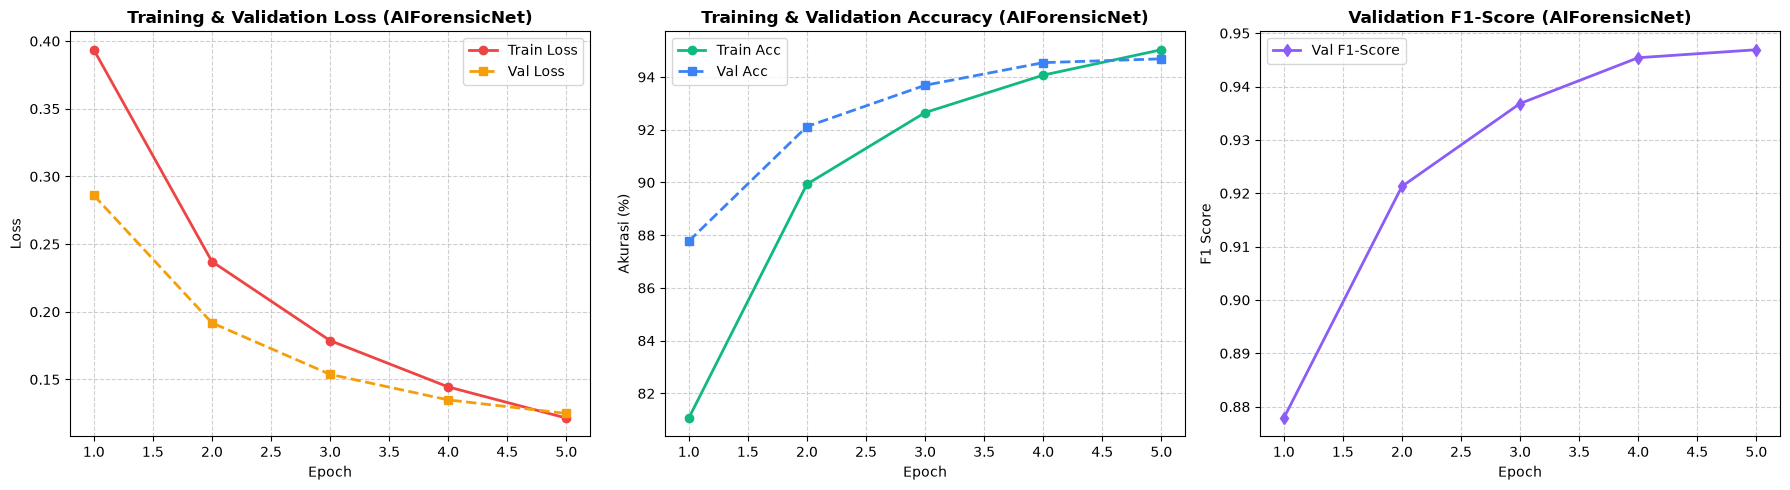

In [6]:
# Visualisasi Kurva Loss, Akurasi, dan F1-Score
epochs_range = range(1, len(history['train_loss']) + 1)

plt.figure(figsize=(18, 5))

# 1. Plot Loss
plt.subplot(1, 3, 1)
plt.plot(epochs_range, history['train_loss'], 'o-', label='Train Loss', color='#EF4444', linewidth=2)
plt.plot(epochs_range, history['val_loss'], 's--', label='Val Loss', color='#F59E0B', linewidth=2)
plt.title('Training & Validation Loss (AIForensicNet)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# 2. Plot Akurasi
plt.subplot(1, 3, 2)
plt.plot(epochs_range, history['train_acc'], 'o-', label='Train Acc', color='#10B981', linewidth=2)
plt.plot(epochs_range, history['val_acc'], 's--', label='Val Acc', color='#3B82F6', linewidth=2)
plt.title('Training & Validation Accuracy (AIForensicNet)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Akurasi (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# 3. Plot Validasi F1-Score
plt.subplot(1, 3, 3)
plt.plot(epochs_range, history['val_f1'], 'd-', label='Val F1-Score', color='#8B5CF6', linewidth=2)
plt.title('Validation F1-Score (AIForensicNet)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Evaluasi Final Validation:   0%|          | 0/478 [00:00<?, ?it/s]

CLASSIFICATION REPORT (AIForensicNet):
                  precision    recall  f1-score   support

AI-Generated (0)     0.9504    0.9496    0.9500      8117
  Real Image (1)     0.9429    0.9438    0.9433      7154

        accuracy                         0.9469     15271
       macro avg     0.9467    0.9467    0.9467     15271
    weighted avg     0.9469    0.9469    0.9469     15271



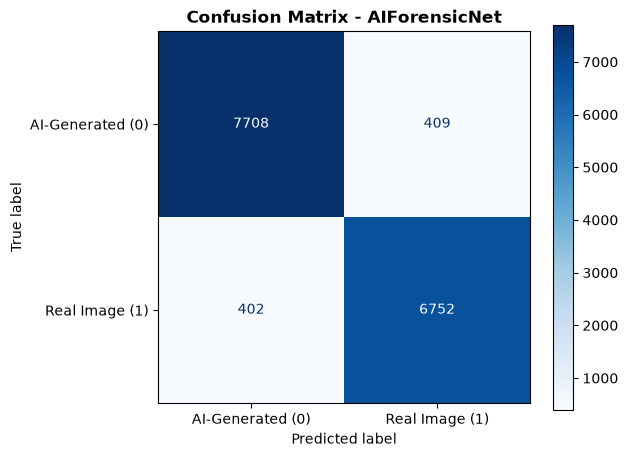

In [7]:
# Evaluasi Mendalam pada Seluruh Data Validasi
model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="Evaluasi Final Validation"):
        images = images.to(device, non_blocking=True)
        if scaler:
            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                outputs = model(images)
        else:
            outputs = model(images)
            
        _, preds = torch.max(outputs, 1)
        y_true.extend(labels.numpy())
        y_pred.extend(preds.cpu().numpy())

target_names = ["AI-Generated (0)", "Real Image (1)"]

print("=" * 65)
print("CLASSIFICATION REPORT (AIForensicNet):")
print("=" * 65)
print(classification_report(y_true, y_pred, target_names=target_names, digits=4))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix - AIForensicNet', fontsize=12, fontweight='bold')
plt.grid(False)
plt.show()

In [8]:
# Fungsi Pengujian Prediksi Citra Tunggal
def predict_image(image_path, model, device):
    """
    Menguji citra tunggal dan mengembalikan prediksi label serta probabilitas kepercayaan.
    """
    if not os.path.exists(image_path):
        print(f"File '{image_path}' tidak ditemukan!")
        return

    img = Image.open(image_path)
    if img.mode == 'P' and 'transparency' in img.info:
        img = img.convert('RGBA')
    img = img.convert('RGB')
    tensor = val_transforms(img).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        if scaler:
            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                outputs = model(tensor)
        else:
            outputs = model(tensor)
            
        probs = torch.softmax(outputs, dim=1)[0]
        ai_prob = probs[0].item() * 100.0
        real_prob = probs[1].item() * 100.0
        pred_class = torch.argmax(probs).item()

    verdict = "AI-Generated Image" if pred_class == 0 else "Real Image"
    confidence = ai_prob if pred_class == 0 else real_prob

    print("=" * 50)
    print(f"File            : {os.path.basename(image_path)}")
    print(f"Hasil Prediksi  : {verdict}")
    print(f"Tingkat Keyakinan: {confidence:.2f}%")
    print(f"  - Probabilitas AI   : {ai_prob:.2f}%")
    print(f"  - Probabilitas Real : {real_prob:.2f}%")
    print("=" * 50)

# Contoh Pengujian dengan beberapa citra uji di workspace
test_files = ["images (2).jpg", "makan.jpeg", "img.png", "test1.webp", "test2.webp", "wa.jpeg", "gani.jpeg", "real.jpg"]
for tf in test_files:
    if os.path.exists(tf):
        predict_image(tf, model, device)

File            : images (2).jpg
Hasil Prediksi  : Real Image
Tingkat Keyakinan: 78.42%
  - Probabilitas AI   : 21.57%
  - Probabilitas Real : 78.42%
File            : makan.jpeg
Hasil Prediksi  : AI-Generated Image
Tingkat Keyakinan: 63.38%
  - Probabilitas AI   : 63.38%
  - Probabilitas Real : 36.60%
File            : img.png
Hasil Prediksi  : AI-Generated Image
Tingkat Keyakinan: 56.54%
  - Probabilitas AI   : 56.54%
  - Probabilitas Real : 43.48%
File            : test1.webp
Hasil Prediksi  : Real Image
Tingkat Keyakinan: 76.42%
  - Probabilitas AI   : 23.58%
  - Probabilitas Real : 76.42%
File            : test2.webp
Hasil Prediksi  : Real Image
Tingkat Keyakinan: 73.68%
  - Probabilitas AI   : 26.29%
  - Probabilitas Real : 73.68%
File            : wa.jpeg
Hasil Prediksi  : Real Image
Tingkat Keyakinan: 99.46%
  - Probabilitas AI   : 0.52%
  - Probabilitas Real : 99.46%
File            : gani.jpeg
Hasil Prediksi  : AI-Generated Image
Tingkat Keyakinan: 82.57%
  - Probabilitas AI 